# E80: Can VPD's adversary fail do-nothing on Qwen3-1.7B, and pass a good placement?

*2026-11-04, D1, `qwen-decomp-lead`. D1 means a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. Record: `reports/analyses/2026-11-04_analysis_e80-adversary.md`.*

**The answer.** On Qwen we can't yet tell whether any method of placing an update into the decomposition holds up. We placed one fine-tune update four ways and read two checks. Doing nothing passes the adversary, and a tenth of the update alone keeps nearly all the gain, so neither check separates the methods on this update. Telling them apart needs a test that can fail a bad placement and an update whose gain builds gradually.

**How far this is checked.** The two later runs, which give this answer, are not independently checked. The first run, told further down, was: `reports/reviews/2026-11-04_review_e80-check.md`.


## What we were trying to test

An update changes a model's weights. D1 asks for a map that moves the decomposition along with the update, and for a test that can fail a bad map. An earlier own-mask read could not be that test, because leaving the whole update out of the subcomponents read as well as the best trained change. So this experiment asks whether VPD's own adversary does better, and whether the methods that worked on the 67M model hold up on Qwen3-1.7B.

It took three runs. The last fills in Qwen's column of the project's scorecard slide, the table that reads four methods on the 67M model. It comes first here because it gives the answer. The first two follow, as the story of how we got there.

**The update.** W0 is Qwen3-1.7B before the update, also called the unchanged decomposition. The update δW is ten steps of a fine-tune on GSM8K maths problems, one saved file. The fine-tuned model is W0 plus δW.

**The adversary.** Each weight matrix is written as rank-one subcomponents plus a leftover Δ. Γ gives each subcomponent a causal importance $g$ from 0 to 1 on each token, reading the state's own weights with its parameters fixed. The adversary gives each subcomponent a setting $s$, shared over all rows and positions, and uses it at strength $m = g + (1-g)s$. It also picks how much of Δ to keep per matrix. From a random start, fixed by its seed, it takes 20 sign steps up the KL from the state's own clean output to its masked output. Zero means the attack changed nothing.

**The four methods, and what each rules out.**

- **Do-nothing**, the worst placement by rule: the fine-tuned weights, components unmoved, the whole update in Δ. If it passes, the check cannot fail anything here.
- **Least-squares split**: the least-norm $(dU, dV)$ with $dU V^\top + U dV^\top \approx \delta W$, moving every alive column. Δ takes the rest, so the weights are the fine-tuned model's.
- **Adjoint split**: $dU = c\,\delta W V$ and $dV = c\,\delta W^\top U$, with one scale $c$ per matrix. The weights become W0 plus the first-order change this makes, and Δ takes nothing.
- **Teacher training**: subcomponents trained towards the fine-tuned model on the clean loss alone, about 200 columns per matrix, in an earlier experiment.

**The three checks**, with the slide's bars.

- **Faithful.** A state's final KL under the adversary over W0's at the same seed, averaged over two seeds, on 128 rows of 512 tokens of web text, the FineWeb rows. W0 reads 1. At or under 1.40 passes, at or over 1.61 fails.
- **Behaviour kept.** The loss with no masks on 256 held-out GSM8K problems, response tokens only. The share is $(L_{W0} - L_{state}) / (L_{W0} - L_{fine\text{-}tuned})$, so W0 reads 0 and the fine-tuned model reads 1. At or over 0.9 is good, under 0.5 is bad.
- **Left in Δ.** The plain share of the update's squared size outside the subcomponents. At or under 10% is good, at or over 30% is bad.

We then read behaviour kept on W0 plus a fraction of the update, to find out whether that check can tell anything apart. This is the alternative it rules out: a share near 1 that any small part of the update would also reach.

## What we expected, and why

We filed leans before the run. Do-nothing and teacher training would pass the adversary, at medium strength, since do-nothing had read 1.28 on web rows earlier. Least squares and the adjoint would pass at low strength; least squares had failed badly on the 67M's full-matrix update. Weakly, we expected the adjoint to keep under half the gain and teacher training over half. The rule said that if do-nothing passes, the table reads "we can't yet tell on Qwen" and no method is called failing. For the fractions, a tenth at or over 0.9 reads "saturated" and at or under 0.5 reads "graded". We leaned, at medium strength, to a tenth keeping over half, because the fine-tune's first step alone has 87% of the gain of its tenth.

## What we observed

The controls held: the scales matched the earlier job's three numbers within 1%, and do-nothing and least squares, which hold the fine-tuned weights, kept 1.00 as they must.

### What does Qwen's column of the scorecard read?


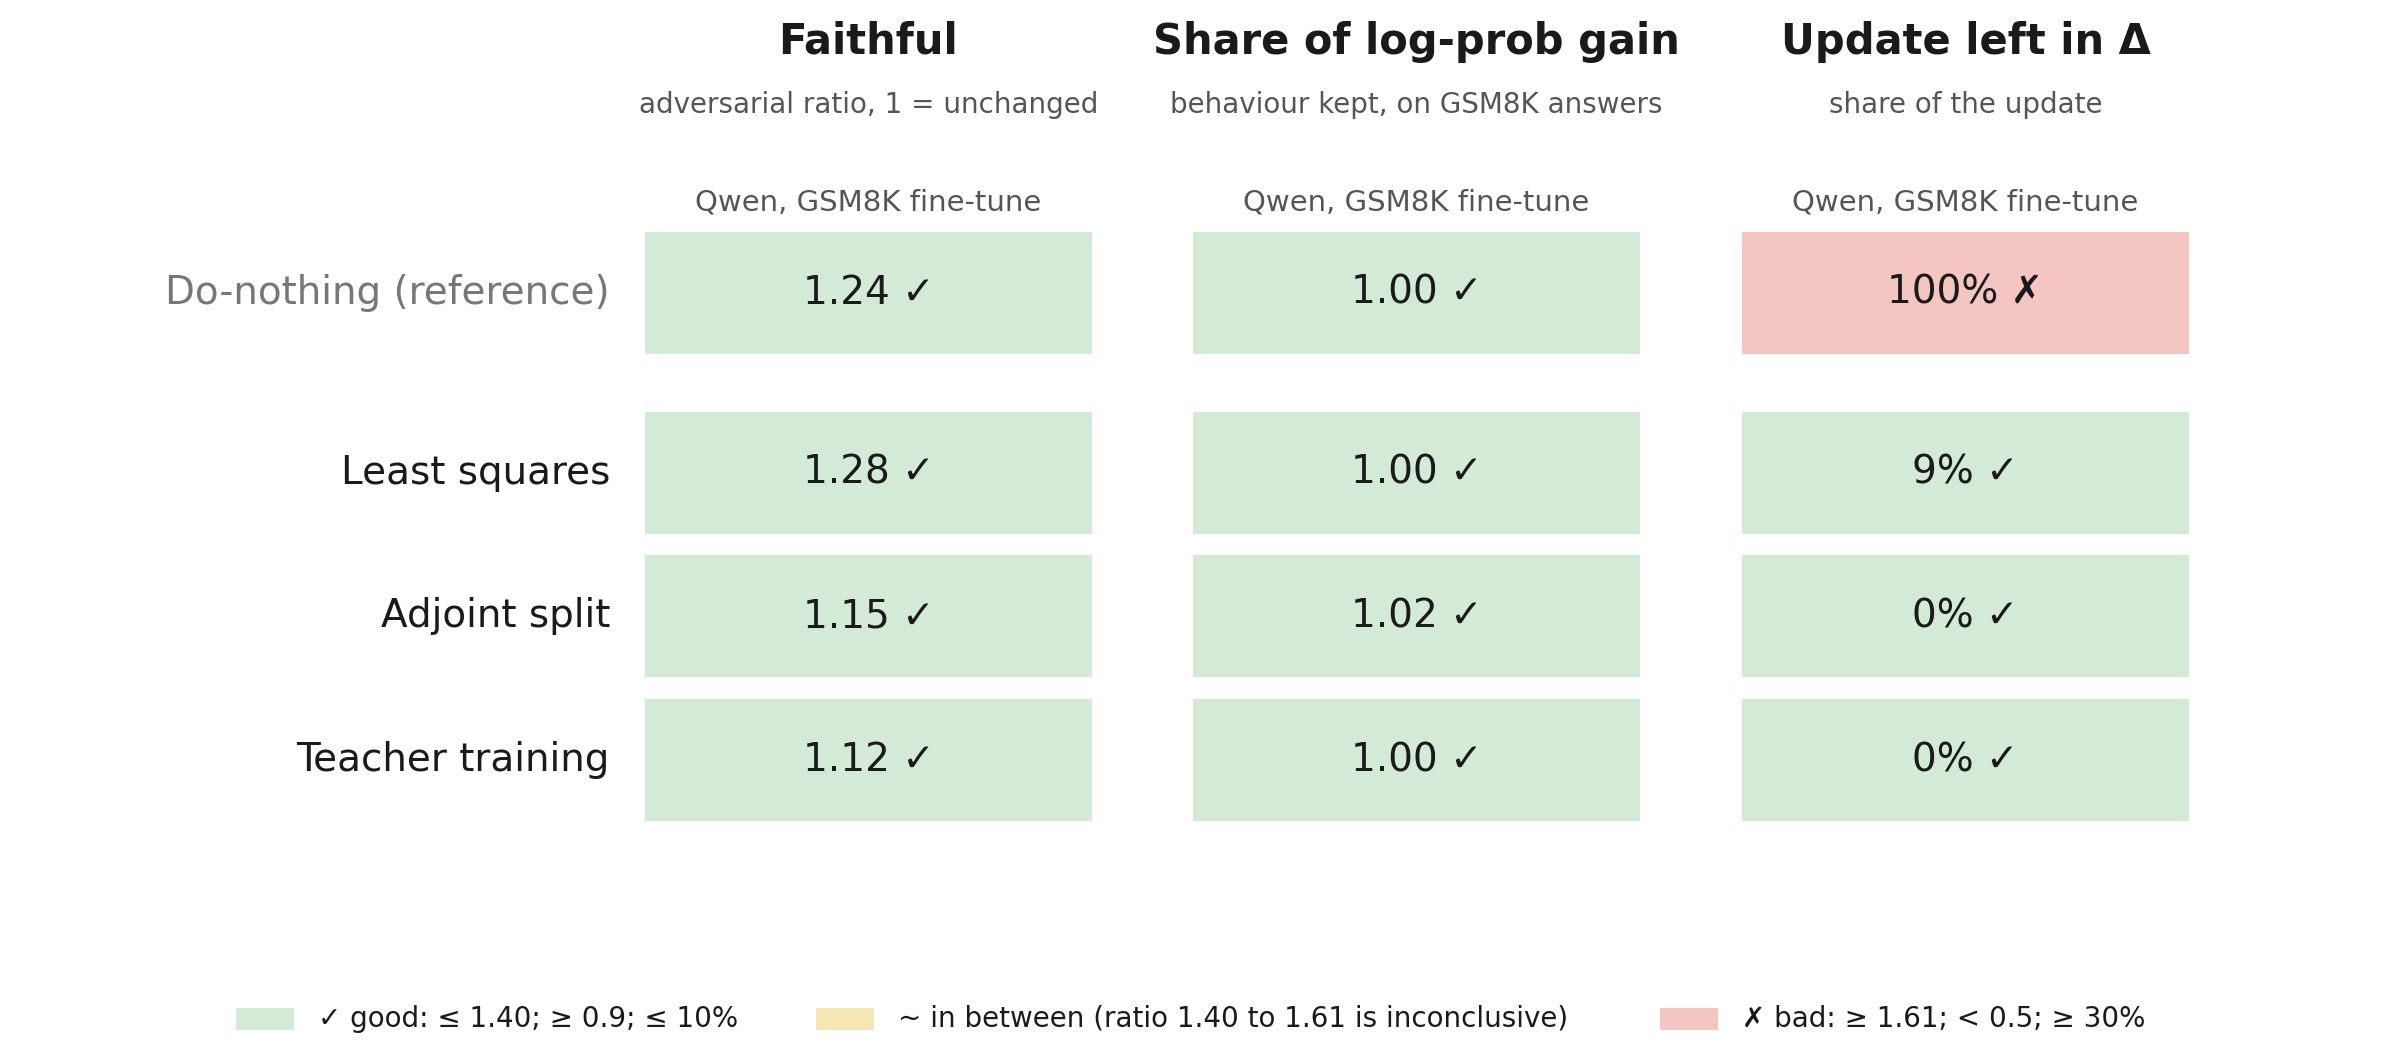

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_d1_adversary")
RES, FIG = ROOT / "results", ROOT / "figures"
R = json.loads((RES / "results.json").read_text())
A1 = json.loads((RES / "amend1.json").read_text())["score"]
A2 = json.loads((RES / "amend2.json").read_text())["score"]
KL = {k: v["kl"] for k, v in R["starts"].items()}
S = R["score"]
W0, W1 = KL["W0_M_s0"], KL["W0_M_s1"]

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

show("scorecard_qwen.png")


**Reading it.** It reads "we can't yet tell on Qwen": all four methods get every check's good mark, apart from do-nothing's Δ, which holds the whole update by construction. The rule for do-nothing passing sets that reading, and no method is called failing. Least squares leaves 9% of the update in Δ on the plain share. Qwen's earlier 36% was an input-weighted norm ratio on another measure, and the user chose the plain share. The next two sections show why the two green columns do not separate the methods.

### Does the adversary fail do-nothing?


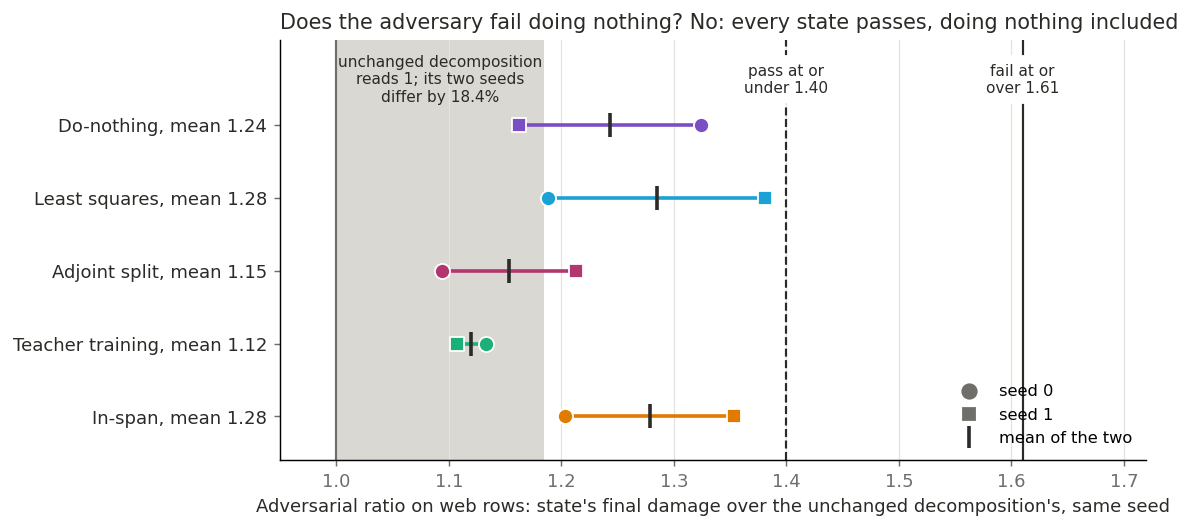

In [2]:
show("faithful_seeds.png")


**Reading it.** No: every state passes, doing nothing included, so this check fails nothing here. Do-nothing reads 1.32 and 1.16 on its two seeds, a mean of 1.24, under the pass bar of 1.40. Least squares reads 1.28, the adjoint 1.15 and teacher training 1.12. W0's own two seeds read 1.703 and 1.438, a spread of 18.4%. Every pair of methods sits closer than that, so no ranking is claimed.

The bars have a real caveat. They come from the 67M's spread between starts, not Qwen's. The same formula with Qwen's spread gives a pass bar near 1.26, which least squares would miss and do-nothing would still clear. We also have no state known to fail on this model, so nothing shows the check can fail one.

The in-span row belongs to the second run, told below.

### Can the kept share tell the methods apart?


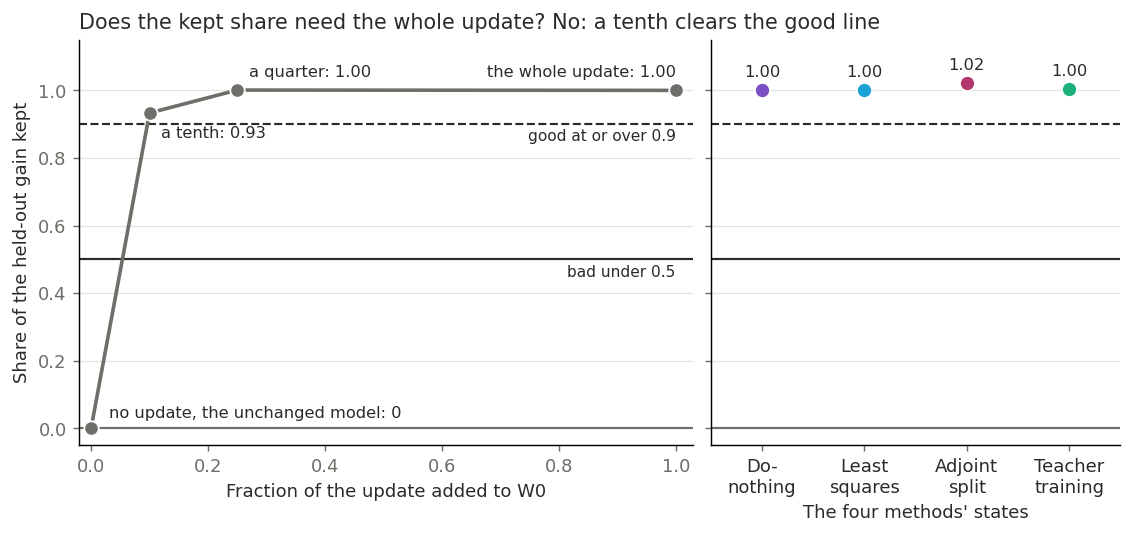

In [3]:
show("kept_fraction.png")


**Reading it.** No: on this update a tenth of it nearly reaches the same share. Adding a tenth of the update to W0 keeps 0.93 of the gain, a quarter keeps 1.00, and the whole update reads 1.00 as the control. By the filed rule that is "saturated", and the medium lean held. The methods' shares of 1.00 to 1.02 are barely above that tenth, so they are not evidence that the methods keep the behaviour. The adjoint's 1.02 reverses our low lean that it would keep under half. The caveat is that this tests only the update's own direction, so it does not say how the adjoint or the teacher reached the gain.

The gain itself is large: the update gains 1.81 of W0's 2.50 nats per token, against 0.13 on the 67M. So a kept share here is not comparable with one there.

## How we got there: the first two runs

The scorecard above did not come first. The first run read the adversary on maths rows, and its filed outcome was more hopeful. Its own caveat and its independent check took most of that back, and the second run tested what was left.

**The first run's states.** W0 at two seeds, and do-nothing, plus two others. **In-span** is the least-squares split's change to the subcomponents with its remainder discarded, the candidate. **A** is the teacher-trained state above, known here by its short name. What A's components hold sits further from the fine-tuned weights than W0's components do.

**The first run's rows and rules.** The rule read 64 maths rows of 256 tokens, unused by any earlier arm. W0 and do-nothing were also read on the 128 web rows, under no rule. The ratio was a state's read over W0's at seed 0. Do-nothing would fail above 1 plus the band, which is W0's start gap with a floor of 0.19. In-span and A shared the slide's bars. We leaned, at medium strength, that do-nothing would read within the band, because masks alone already reach near the fine-tuned output with Δ off. We leaned weakly that in-span would pass.

**The filed outcome.** By the filed rule the outcome is "D1 has a test and a first candidate". It stands as filed, and it is worth little. The adversary read do-nothing about a third above W0. But that same empty state sits under the pass bar, and the placements read closer to it than two starts on W0 read to each other.

**Something unexpected happened that I cannot explain.** The medium lean said do-nothing would read within the band. It read 1.317 times W0, over a bar of 1.19, which reverses the lean. Our weak lean that in-span passes held. No cause is claimed.

**The independent check.** Every score recomputes and no bug was found in the code paths it read, but the filed outcome's plain meaning is not supported. Its main addition is in the first reading below.

### Does the adversary read do-nothing above W0, and do the bars separate it from the placements?


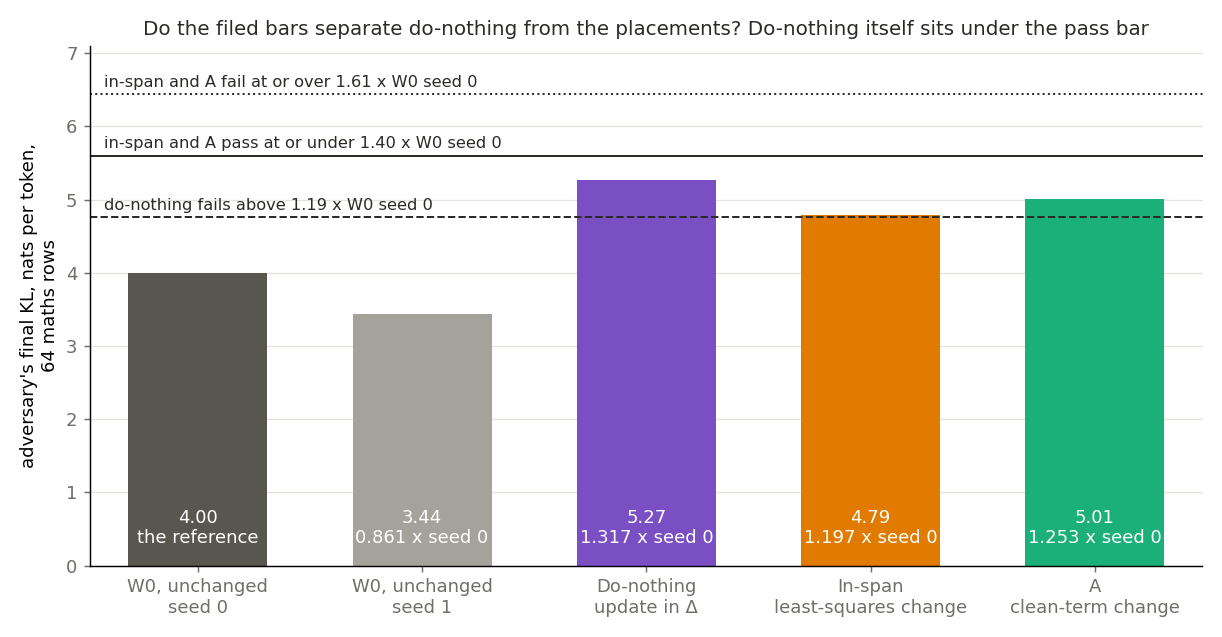

| maths rows | final KL | over W0 seed 0 | over W0 seed 1 | filed verdict |
|---|---|---|---|---|
| W0, seed 0 | 4.00 | 1 | 1.16 | reference |
| W0, seed 1 | 3.44 | 0.861 | 1 | sets the band |
| do-nothing | 5.27 | 1.317 | 1.53 | fails do-nothing |
| in-span | 4.79 | 1.197 | 1.39 | passes |
| A | 5.01 | 1.253 | 1.46 | passes, for report |

In [4]:
show("adversary_maths.png")
table(["maths rows", "final KL", "over W0 seed 0", "over W0 seed 1", "filed verdict"],
      [["W0, seed 0", f"{W0:.2f}", 1, f"{W0 / W1:.2f}", "reference"], ["W0, seed 1", f"{W1:.2f}", f"{W1 / W0:.3f}", 1, "sets the band"]]
      + [[name, f"{KL[k + '_M_s0']:.2f}", f"{S['r'][k]:.3f}", f"{KL[k + '_M_s0'] / W1:.2f}", v]
         for name, k, v in (("do-nothing", "N", S["do_nothing"]), ("in-span", "I", S["inspan"]), ("A", "A", S["A"] + ", for report"))])


**Reading it.** Do-nothing reads above W0 at both W0 starts, and the bars do not separate it from the placements. Do-nothing reads 5.27 against W0's 4.00 and 3.44. On FineWeb rows, under no rule, it reads 2.25 against 1.75. So by the filed rule the outcome is "D1 has a test and a first candidate", and it stands.

The caveat decides how much that outcome is worth, because the filed bars do not cohere. Do-nothing's 1.317 is itself under the in-span pass bar of 1.40. In-span's 1.197 is over do-nothing's fail bar of 1.19, by 0.007. Do-nothing and in-span differ by about 10%, less than W0's own start-to-start 16%, and each has one start. So this run shows the adversary reads do-nothing above W0. It does not show that it reads in-span below do-nothing, nor that in-span is a good placement, and the ordering of the three is not read as a result. Against W0's second start the ratios rise: do-nothing 1.53, A 1.46, in-span 1.39.

The check adds that on the maths rows the ratio is there at step 0, before the attack: do-nothing 1.44, A 1.42, in-span 1.34 times W0. On FineWeb do-nothing starts at 1.005 and the attack raises it to 1.28. So "do-nothing fails on maths" cannot be read as "the adversary found the update in Δ". A candidate cause is that the maths rows are W0's own answers, so W0 is read against very different clean outputs from the other states; that is not measured. The bars stand as filed; this is a reading beside them. No cause is claimed for do-nothing's rise: this job does not separate Δ carrying behaviour from a change in which subcomponents Γ switches on, or from anything else.

### Does the read follow how much of the update the components hold?


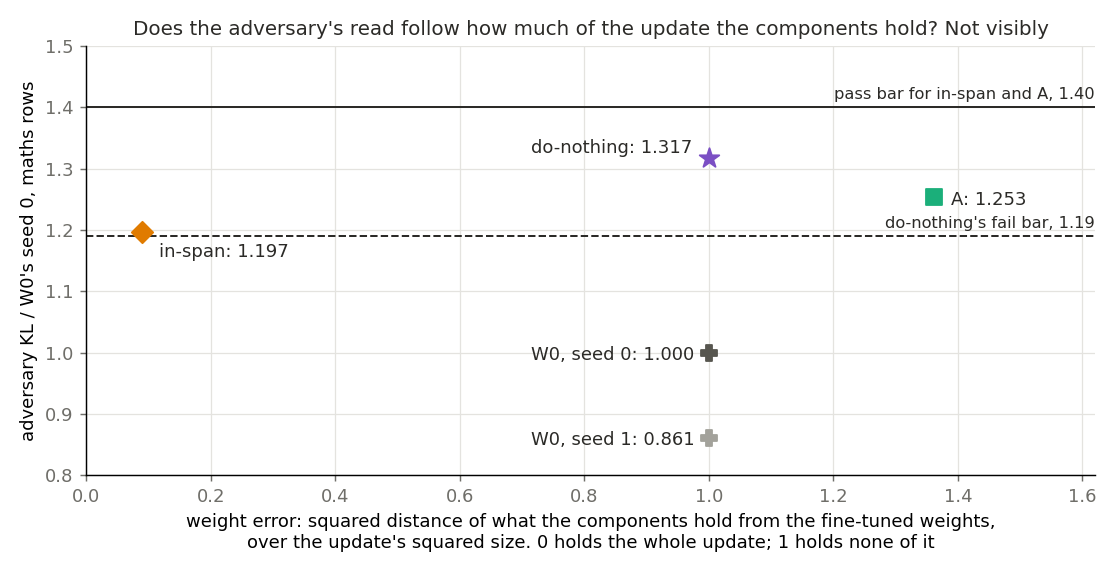

| state | weight error | ratio | clean KL to fine-tuned | self, E79's maths rows |
|---|---|---|---|---|
| W0 | 1 | 1 | 1.842 | 0.043 |
| do-nothing | 1.00 | 1.317 | about 0 | 0.066, E79 |
| in-span | 0.09 | 1.197 | 0.0094 | 0.062 |
| A | 1.36 | 1.253 | 0.012, E76 | 0.065, E79 |

In [5]:
show("weight_error.png")
w = R["weights"]
table(["state", "weight error", "ratio", "clean KL to fine-tuned", "self, E79's maths rows"],
      [["W0", 1, 1, f"{R['own']['W0']['M']['clean']:.3f}", f"{R['own']['W0']['M']['self']:.3f}"],
       ["do-nothing", f"{w['N']:.2f}", f"{S['r']['N']:.3f}", "about 0", "0.066, E79"],
       ["in-span", f"{w['I']:.2f}", f"{S['r']['I']:.3f}", f"{R['own']['I']['M']['clean']:.4f}", f"{R['own']['I']['M']['self']:.3f}"],
       ["A", f"{w['A']:.2f}", f"{S['r']['A']:.3f}", "0.012, E76", "0.065, E79"]])


**Reading it.** Not visibly, on these three states. Weight error is the squared distance of what the components hold from the fine-tuned weights, over the update's squared size: 0 holds the whole update, 1 holds none. In-span reads 0.09 and a ratio of 1.197. Do-nothing reads 1 and 1.317. A reads 1.36, worse than do-nothing, and its ratio of 1.253 passes the same bar as the candidate. Three points with one start each cannot show a trend or the lack of one, so this says only that the read has not yet been shown to grade placement.

### Had the search finished, and how steady is one read?


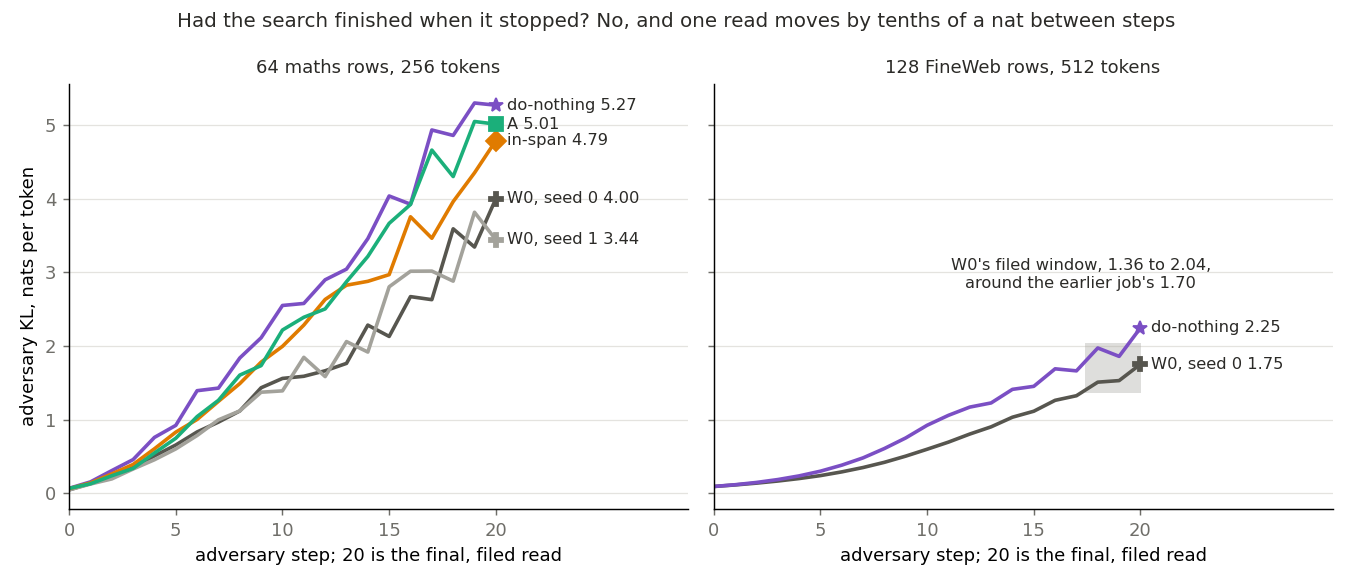

In [6]:
show("steps.png")


**Reading it.** The search had not finished, so every read is a lower bound. On FineWeb rows W0 was rising about 9.5% per step over its last five steps, and do-nothing about 9%. Maths rows also move by tenths of a nat between neighbouring steps: W0's seed 0 rose 0.66 at its last step and seed 1 fell 0.37, which swaps the two starts. That last move is larger than the gap between do-nothing and in-span, 0.48. The filed read is the final one, and it stands.

### On web rows, does the adversary read in-span below do-nothing?

The check showed that web rows are where the attack itself makes the rise: do-nothing starts at 1.005 and ends at 1.28. So the second run read do-nothing, in-span and A there, at two seeds paired across states. It leaned that do-nothing's rise would reproduce and that in-span would not separate from it. The figure is the one under "Does the adversary fail do-nothing?" above.

**Reading it.** No: the filed outcome is "cannot tell in-span from do-nothing on web rows". Do-nothing's rise reproduced, at 1.16 on the second seed, and both leans held. In-span reads 1.20 and 1.35 against do-nothing's 1.32 and 1.16, so the two swap order between seeds. Teacher training reads below do-nothing on both seeds, but by an average factor of 1.11, inside the 1.14 the rule required. The first run had proposed repeating starts paired by seed; this did so on web rows, and it did not separate the placements.

## What we learned

The first run suggested the adversary might mark do-nothing as worse than W0, and it still reads above W0 on every seed. But it does not fail do-nothing by the bars, and it does not separate in-span, least squares, the adjoint or teacher training from it. Behaviour kept cannot separate them either on this update, since a tenth of the update nearly reaches it. So for `GOALS.md`, whether the 67M's methods hold up at Qwen's scale is unanswered, neither supported nor refuted. D1 still lacks a test that passes a good placement over a bad one, and the filed "first candidate" is a label only.

## How compelling is the evidence

Good enough to say these two checks do not separate the methods on this update, and silent on which method is better. There is one update, with two seeds of each state in the scorecard.

- **A lower bound.** The adversary was still rising at step 20 on web rows.
- **The rows.** The update moves clean outputs little on web text, a KL of 0.04, so Faithful is not read on maths text. The first run's maths rows compare only with each other, because a shared setting has fewer rows to satisfy.
- **The bars.** They are the 67M's, not measured on Qwen.
- **No positive control for failure.** No state known to fail on this model was read.
- **Blind to.** Faithful does not see which subcomponents carry the update. Behaviour kept reads weights only, never the moved subcomponents, and left in Δ counts every weight direction alike.
- **Hosts.** Seed 0's ratios cross two machines of one card model. Three steps of W0 at seed 0 matched to the four places logged.

## Surprises

The first run's reversal leads: the medium lean said do-nothing would read within the band on maths rows, and it read over the bar. I cannot explain it. In the scorecard, one low lean reversed: the adjoint keeps 1.02 of the gain where we leaned under half; no cause is claimed. Beside that, A's weight error of 1.36 did not stop it passing, and W0's two starts swap order at the last step of the maths rows.

## What next

These are proposals, not results, and the details come from the lead. Two amendments have been used, so each is a new plan.

- **D1's test.** The plan's filed step for "cannot tell" is that the adversary is out as D1's test. D1's restatement then goes to the user, with the fallback of the clean table with Δ untouched and wrong-direction nulls.
- **A bad placement of the same size.** If the adversary fails it, the check has some power and might come back. If it passes, nothing here can fail a placement.
- **An update whose gain builds gradually.** If a tenth of that update keeps well under the good line, kept shares start to mean something for the adjoint and the teacher.
- **A third start of all states,** the user's call if two seeds leave a decision ambiguous.

## Scorecard


In [7]:
table(["id", "claim", "rule", "read", "verdict"], [
    ["stage 1", "W0 on W reproduces the earlier job", "1.36 to 2.04", f"{KL['W0_W_s0']:.3f}", "in the window" if S["stage1_in_window"] else "outside"],
    ["do_nothing", "the adversary fails do-nothing", f"r(N) > 1 + {S['b']}", f"{S['r']['N']:.3f}", f"\"{S['do_nothing']}\"; medium lean \"within the band\" reversed"],
    ["inspan", "the adversary passes in-span", "r(I) ≤ 1.40 passes, ≥ 1.61 fails", f"{S['r']['I']:.3f}", f"\"{S['inspan']}\"; weak lean held"],
    ["A", "same bars, for report", "as in-span", f"{S['r']['A']:.3f}", f"\"{S['A']}\""],
    ["outcome", "fails do-nothing and in-span passes", "as filed", "", f"\"{S['outcome']}\", stands as filed"],
    ["W", "reported as read", "none", f"r(N) {S['W_as_read']['r_N']:.3f}", "as read"],
    ["A1 reproduces", "do-nothing's rise holds at seed 1 on W", "r_1(N) > 1", f"{A1['r']['N'][1]:.3f}", f"\"{A1['reproduces']}\"; medium lean held"],
    ["A1 I", "in-span reads below do-nothing on W", f"both seeds and gap > 1 + {A1['b']:.3f}", f"gap {A1['gap']['I']:.3f}", f"\"{A1['separated']['I']}\"; medium lean held"],
    ["A1 A", "A reads below do-nothing on W", "as above", f"gap {A1['gap']['A']:.3f}", f"\"{A1['separated']['A']}\""],
    ["A1 outcome", "the adversary follows placement on W", "as filed", "", f"\"{A1['outcome']}\""],
] + [[f"A2 {k}", f"{name} on Faithful", "mean ≤ 1.40 passes, ≥ 1.61 fails", f"{A2['mean'][k]:.3f}", f"\"{A2['verdict'][k]}\"; {lean} lean held"]
     for k, name, lean in (("N", "do-nothing", "medium"), ("LS", "least squares", "low"), ("ADJ", "adjoint", "low"), ("A", "teacher", "medium"))] + [
    ["A2 reading", "do-nothing's row sets the table", "do-nothing passes", "", f"\"{A2['reading']}\""],
    ["A2 kept ADJ", "adjoint keeps under half", "lean only", f"{A2['kept']['ADJ']:.3f}", "low lean reversed"],
    ["A2 kept A", "teacher keeps over half", "lean only", f"{A2['kept']['A']:.3f}", "low lean held"],
    ["A2 fractions", "a tenth of the update keeps the gain", "≥ 0.9 saturated, ≤ 0.5 graded", f"{(A2['gold']['W0'] - A2['gold']['t0.1']) / A2['gain']:.3f}", "\"saturated\"; medium lean held"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| stage 1 | W0 on W reproduces the earlier job | 1.36 to 2.04 | 1.752 | in the window |
| do_nothing | the adversary fails do-nothing | r(N) > 1 + 0.19 | 1.317 | "fails do-nothing"; medium lean "within the band" reversed |
| inspan | the adversary passes in-span | r(I) ≤ 1.40 passes, ≥ 1.61 fails | 1.197 | "passes"; weak lean held |
| A | same bars, for report | as in-span | 1.253 | "passes" |
| outcome | fails do-nothing and in-span passes | as filed |  | "D1 has a test and a first candidate", stands as filed |
| W | reported as read | none | r(N) 1.282 | as read |
| A1 reproduces | do-nothing's rise holds at seed 1 on W | r_1(N) > 1 | 1.162 | "reproduces"; medium lean held |
| A1 I | in-span reads below do-nothing on W | both seeds and gap > 1 + 0.139 | gap 0.980 | "not separated"; medium lean held |
| A1 A | A reads below do-nothing on W | as above | gap 1.109 | "not separated" |
| A1 outcome | the adversary follows placement on W | as filed |  | "cannot tell in-span from do-nothing on W" |
| A2 N | do-nothing on Faithful | mean ≤ 1.40 passes, ≥ 1.61 fails | 1.244 | "pass"; medium lean held |
| A2 LS | least squares on Faithful | mean ≤ 1.40 passes, ≥ 1.61 fails | 1.285 | "pass"; low lean held |
| A2 ADJ | adjoint on Faithful | mean ≤ 1.40 passes, ≥ 1.61 fails | 1.153 | "pass"; low lean held |
| A2 A | teacher on Faithful | mean ≤ 1.40 passes, ≥ 1.61 fails | 1.120 | "pass"; medium lean held |
| A2 reading | do-nothing's row sets the table | do-nothing passes |  | "we can't yet tell on Qwen" |
| A2 kept ADJ | adjoint keeps under half | lean only | 1.021 | low lean reversed |
| A2 kept A | teacher keeps over half | lean only | 1.003 | low lean held |
| A2 fractions | a tenth of the update keeps the gain | ≥ 0.9 saturated, ≤ 0.5 graded | 0.933 | "saturated"; medium lean held |

## Departures from the literature

The adversary follows VPD's evaluation config. Departures, in full in the report:

- **A changed model.** VPD runs it on the model its decomposition was fitted to. Here Γ is frozen and reads weights it was not fitted to.
- **Rows.** VPD's evaluation here uses 128 rows of 512 tokens, kept for the web rows. The first run's rule reads 64 maths rows of 256 tokens.
- **Ratio and bars.** VPD reports the KL alone. The ratio, the 1.40, the 1.61 and the 0.19 are this project's, the first two carried unchanged from the 67M model.
- **Starts.** The first run has one start per state and the scorecard two, final step only. These are the filed rules' choices.
- **Precision.** Components in fp32 and Γ in bf16, as the earlier job. The authors' bf16 autocast cannot hold these moved columns.
- **The placements.** The least-squares split and teacher training have no published source. In-span discards the remainder where `GOALS.md`'s split sends it to Δ.

**Differences from the 67M's numbers on the slide**, as read:

- **The adversary.** Its settings match the 67M's: 20 sign steps of 0.1, one source per site, final read. It differs in two seeds rather than one, web rows rather than Pile, one block of 128 rows rather than two, fp32 components, batch 1, and the card.
- **The bars.** They come from the 67M's spread, not Qwen's.
- **The update.** Its gain is 1.81 of 2.50 nats, against 0.13 on the 67M.
- **The teacher.** This state moves 200 columns per matrix at Adam 1e-6 on maths and web rows, where the 67M's recipe moves all alive columns at 1e-5.
- **The adjoint's scale.** It is taken on the update's own first training rows, as on the 67M. The earlier scale on maths rows lies within about 11% at every matrix.

## Not run

First run and second run:

1. A second start of do-nothing, in-span or A on the maths rows, or a paired spread there.
2. Any state known to be a bad placement of the right size.
3. More than 20 steps, so the plateau is unknown.
4. Other updates, steps or tasks, and maths rows at the 128-row scale.
5. Which subcomponents the attack or the update uses.

Scorecard:

1. A third start of any state.
2. A bad placement of the same size.
3. A random direction at the same size.
4. More than 20 adversary steps.
5. Kept shares on an update whose gain builds gradually.
6. The maths rows for least squares and the adjoint.

## Provenance

Results `experiments/qwen_d1_adversary/results/`: `results.json` for the first run, `amend1.json` and `amend2.json` for the others. Figures from `plot.py`, `plot_scorecard.py` and `plot_amend2.py`. First run: one RunPod H100 PCIe, 1.94 h of run from the log, peak GPU 66.1 GB, $6.21 billed. Amendments 1 and 2 ran on two H200 NVL pods on Vast. The plan estimated about $18 and $7 for them; their bills are not in the report. Amendments 1 and 2 are not independently checked.
